# Task 5: Feature engineering

Features support cancellation classification and ADR regression. Every model feature must be known when the booking is created. Outcome fields and values accumulated after booking are excluded.


In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
SLIDE_DIR = Path('../slides')
MODEL_DIR = Path('../models')
for folder in [DATA_DIR, OUTPUT_DIR, SLIDE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv(DATA_DIR / 'hotel_bookings_clustered.csv', parse_dates=['arrival_date'])
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['has_children'] = ((df['children'] + df['babies']) > 0).astype('int8')
df['family_booking'] = ((df['adults'] > 0) & (df['has_children'] == 1)).astype('int8')
df['weekend_share'] = np.where(df['total_nights'].gt(0), df['stays_in_weekend_nights'] / df['total_nights'], 0)
df['arrival_weekday'] = df['arrival_date'].dt.day_name()
df['arrival_month'] = df['arrival_date'].dt.month.astype('int8')
df['is_weekend_arrival'] = df['arrival_date'].dt.weekday.ge(5).astype('int8')
df['price_per_guest'] = np.where(df['total_guests'].gt(0), df['adr'] / df['total_guests'], np.nan)
df['lead_time_band'] = pd.cut(df['lead_time'], [-1,7,30,90,180,np.inf], labels=['0-7','8-30','31-90','91-180','181+']).astype(str)
prior_total = df['previous_cancellations'] + df['previous_bookings_not_canceled']
df['previous_cancel_rate'] = np.where(prior_total.gt(0), df['previous_cancellations'] / prior_total, 0)
df['is_direct_channel'] = df['distribution_channel'].eq('Direct').astype('int8')
df['has_parking_request'] = df['required_car_parking_spaces'].gt(0).astype('int8')


## Feature register

`price_per_guest` is available for cancellation prediction because ADR is already quoted, but it is excluded from ADR regression because it contains the regression target.


In [3]:
feature_register = pd.DataFrame([
    ['total_nights','Requested stay length','Yes','Both'],
    ['total_guests','Adults plus children plus babies','Yes','Both'],
    ['has_children','Booking includes a child or baby','Yes','Both'],
    ['family_booking','Adult booking with a child or baby','Yes','Both'],
    ['weekend_share','Weekend nights divided by total nights','Yes','Both'],
    ['arrival_weekday','Planned arrival weekday','Yes','Both'],
    ['arrival_month','Planned arrival month','Yes','Both'],
    ['is_weekend_arrival','Arrival is Saturday or Sunday','Yes','Both'],
    ['price_per_guest','Quoted ADR divided by total guests','Yes','Cancellation only'],
    ['lead_time_band','Booking horizon band','Yes','Both'],
    ['previous_cancel_rate','Historical cancellations divided by prior bookings','Yes','Both'],
    ['is_direct_channel','Direct distribution channel flag','Yes','Both'],
    ['has_parking_request','Parking requested at booking','Yes','Both'],
    ['cluster_name','Training-only guest segment from Task 3','Yes','Both'],
], columns=['feature','definition','known_in_advance','model_use'])
display(feature_register)
feature_register.to_csv(OUTPUT_DIR / 'feature_register.csv', index=False)


                 feature  ...          model_use
0           total_nights  ...               Both
1           total_guests  ...               Both
2           has_children  ...               Both
3         family_booking  ...               Both
4          weekend_share  ...               Both
5        arrival_weekday  ...               Both
6          arrival_month  ...               Both
7     is_weekend_arrival  ...               Both
8        price_per_guest  ...  Cancellation only
9         lead_time_band  ...               Both
10  previous_cancel_rate  ...               Both
11     is_direct_channel  ...               Both
12   has_parking_request  ...               Both
13          cluster_name  ...               Both

[14 rows x 4 columns]


                 feature  ...          model_use
0           total_nights  ...               Both
1           total_guests  ...               Both
2           has_children  ...               Both
3         family_booking  ...               Both
4          weekend_share  ...               Both
5        arrival_weekday  ...               Both
6          arrival_month  ...               Both
7     is_weekend_arrival  ...               Both
8        price_per_guest  ...  Cancellation only
9         lead_time_band  ...               Both
10  previous_cancel_rate  ...               Both
11     is_direct_channel  ...               Both
12   has_parking_request  ...               Both
13          cluster_name  ...               Both

[14 rows x 4 columns]

Saved model-ready data: (119209, 60)


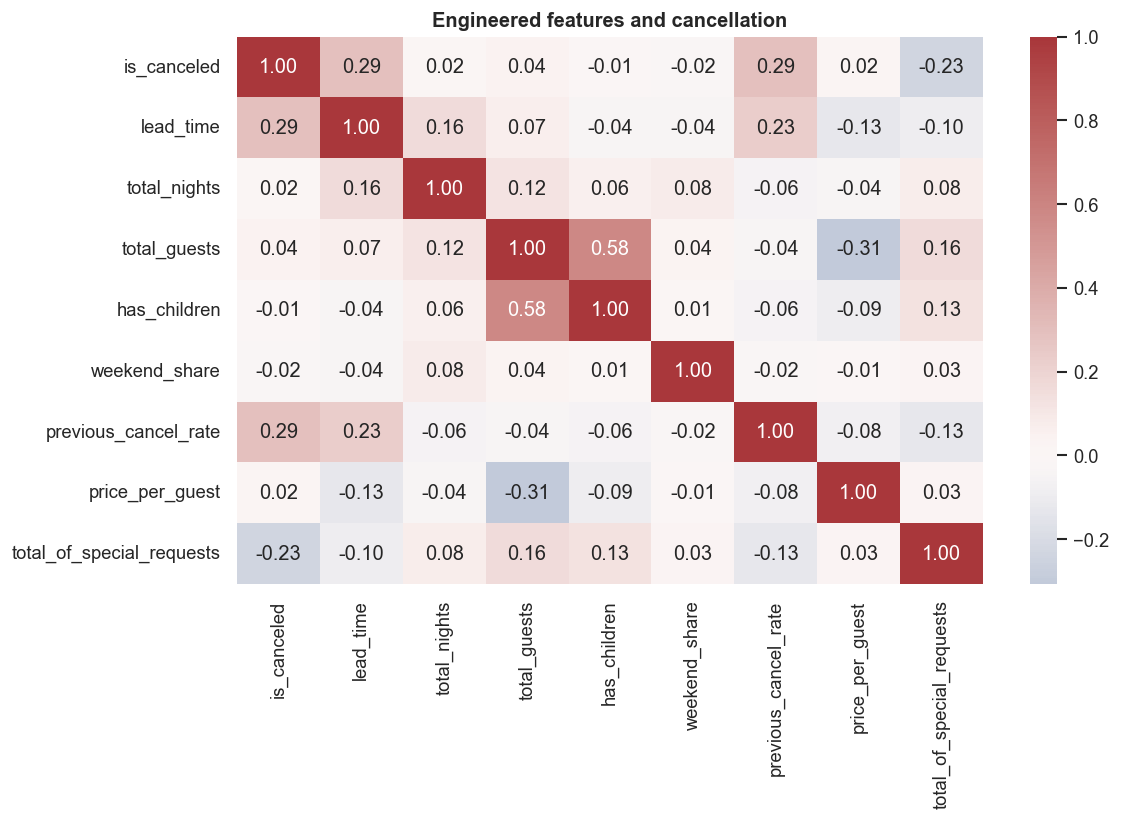

In [4]:
corr_cols = ['is_canceled','lead_time','total_nights','total_guests','has_children','weekend_share','previous_cancel_rate','price_per_guest','total_of_special_requests']
corr = df[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, cmap='vlag', center=0, annot=True, fmt='.2f', ax=ax)
ax.set_title('Engineered features and cancellation', fontweight='bold')
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'feature_correlations.png', bbox_inches='tight'); plt.show()

df.to_csv(DATA_DIR / 'hotel_bookings_model_ready.csv', index=False)
print('Saved model-ready data:', df.shape)


## Leakage exclusions

The models exclude `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes` and `days_in_waiting_list`. These fields contain the outcome or can change after the prediction moment. ADR regression also excludes `adr`, `price_per_guest` and every field derived from ADR.
